# Tutorial 12: Planar Capacitance Families in SQuADDS

SQuADDS now holds about 60,000 new layouts of capacitors and qubits: paddle, concentric, star and multipad star couplers, shielded concentric capacitors, Xmon and `TransmonPocket` qubits, and more. Each one was simulated in Ansys Q3D and comes with its **full $N \times N$ Maxwell capacitance matrix**. Before we pick a design from this data, or trust a model trained on it, we should know what is in it. In this tutorial we see every dataset at a glance, meet the families, look at everything the dataset stores for one design, and use the same data in the classic SQuADDS workflow.

**Note:** the dataset is `SQuADDS/SQuADDS_PlanarCapacitance` on Hugging Face. A local copy works too: point the environment variable `SQUADDS_PLANAR_CAP_DATA` at it. Nothing in this tutorial needs the ML extra.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

## Why a new dataset?

Until now, the capacitance data in SQuADDS came one component at a time: a `TransmonCross` and its claw, an interdigital capacitor between two lines. Real chips keep getting more connected. A coupler talks to three qubits at once, a qubit has a readout claw *and* a bus claw, a guard ring sits between two pads. In each of these, every conductor talks to every other one, so what we need is the full **Maxwell capacitance matrix** $C$:

$$Q_i = \sum_j C_{ij} V_j .$$

For $N$ conductors (the ground plane counts as one), $C$ is a symmetric $N \times N$ matrix with positive diagonal entries (the self capacitances) and negative off-diagonal entries ($C_{ij} = -C^{\rm mutual}_{ij}$). In a closed system every row sums to zero once the ground is included ($\sum_j C_{ij} = 0$), and the signal block is positive definite.

The dataset stores exactly that for every layout, with a few conventions we will see over and over:

- capacitances in **fF**, Maxwell signs, ground **`G` first**, then the signal conductors (`N`, `S`, `P1`, ...),
- the number of conductors $N$ is read from the layout, and **nets are never merged**,
- the reference label is the last complete adaptive pass of the Q3D solve, on silicon ($\varepsilon_r = 11.45$, 350 µm thick) with zero-thickness metal.

Let's go meet the families!

In [2]:
import os

os.environ["QISKIT_METAL_HEADLESS"] = "1"

import warnings

warnings.filterwarnings("ignore")

In [3]:
import json

import gdstk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import squadds

Importing SQuADDS switches the inline figures of a notebook to PDF / SVG (a setting it inherits from scqubits), so let's switch back to PNG.

In [4]:
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("png")

SQuADDS also logs every web request it makes to Hugging Face. Let's keep the notebook quiet.

In [5]:
import logging

logging.getLogger("httpx").setLevel(logging.WARNING)
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

## Connecting to the dataset

`PlanarCapacitanceDB` is the read-only door to the dataset. It reads one Parquet file at a time and only the columns and rows we ask for, so a query never loads more than it needs. It needs nothing beyond a plain `pip install squadds`.

In [6]:
from squadds.ml.capacitance.dataset import PlanarCapacitanceDB

pdb = PlanarCapacitanceDB()

These are the tables we can query:

In [7]:
list(pdb.tables())

['designs',
 'layouts',
 'simulations',
 'labels',
 'label_passes',
 'geometric_embedding_nodes',
 'geometric_embedding_edges',
 'geometric_embedding_globals',
 'physics_prior',
 'optimized_physics_prior',
 'model_input']

The first five are the **raw** tables. The rest are **processed** tables, computed from the layouts:

| table | what it holds |
|---|---|
| `designs` | one row per design, with the options that generated it |
| `layouts` | one row per GDS file |
| `simulations` | one row per Q3D solve |
| `labels` | the final Maxwell matrices |
| `label_passes` | every adaptive pass of each solve |
| `geometric_embedding_*` | the geometric embedding (conductors, pairs, globals) |
| `physics_prior`, `optimized_physics_prior` | the physics prior and the extrapolated (optimized) prior |
| `model_input` | the packed input of the planar capacitance models |

We'll go through all of them.

## A first look: families, sizes and splits

Let's pull a few columns of the `designs` table for every design:

In [8]:
designs = pdb.designs(columns=["design_id", "collection", "paper_family", "component_class", "n_conductors", "split"])
len(designs)

60159

In [9]:
designs.head()

,design_id,collection,paper_family,component_class,n_conductors,split
0,ref/twonet/q3d_cap_0017,twonet,single conductor in a ground cut,None,2.0,excluded
1,ref/twonet/q3d_cap_0038,twonet,single conductor in a ground cut,None,2.0,excluded
2,ref/twonet/q3d_cap_0071,twonet,single conductor in a ground cut,None,2.0,excluded
3,ref/twonet/q3d_cap_0075,twonet,single conductor in a ground cut,None,2.0,excluded
4,ref/twonet/q3d_cap_0120,twonet,single conductor in a ground cut,None,2.0,excluded


Every design has a `design_id` of the form `ref/<collection>/<design>`. The collections `exp6` to `exp15` are parametric sweeps of one component each, so they come with a **SQuADDS component class** that rebuilds them. The other collections (random shape placements, mixed-shape layouts, two-net layouts, lattices, ...) are off-design sets that teach the models physics. They have no quantum-metal component.

In [10]:
sweeps = designs[designs.collection.str.fullmatch(r"exp\d+") & designs.component_class.notna()]
sweeps.groupby("collection", sort=False).agg(
    family=("paper_family", "first"), component=("component_class", "first"), designs=("design_id", "size")
).sort_index(key=lambda c: c.str[3:].astype(int))

,family,component,designs
collection,,,
exp6,interdigital,GeneralizedCapNInterdigital,1563
exp7,interdigital,GeneralizedCapNInterdigital,1440
exp8,interdigital,GeneralizedCapNInterdigital,16380
exp9,paddle,GeneralizedCapNInterdigital,15000
exp10,concentric,GeneralizedCapConcentric,1981
exp11,star,GeneralizedCapStar,1959
exp12,multipad star,GeneralizedCapStar,1833
exp13,Xmon,Xmon,1500
exp14,TransmonPocket,TransmonPocket,1500


How many conductors do they have? Remember that $N$ counts the ground:

In [11]:
pd.crosstab(sweeps.paper_family, sweeps.n_conductors)

n_conductors,3.0,4.0,5.0,6.0,7.0
paper_family,,,,,
TransmonPocket,0,354,226,0,0
Xmon,398,377,0,0,0
concentric,1981,0,0,0,0
interdigital,19383,0,0,0,0
multipad star,0,469,464,453,444
paddle,15000,0,0,0,0
shielded concentric,166,187,47,0,0
star,1959,0,0,0,0


Every design also sits in one **split**. `train` and `val` are what the models learned from and were tuned on. `test` holds the layouts set aside to score them (more on that at the end). We'll use `train` and `val` designs throughout.

In [12]:
pd.crosstab(designs.paper_family, designs.split, margins=True)

split,excluded,none,test,train,val,All
paper_family,,,,,,
TransmonPocket,0,920,171,361,48,1500
Xmon,0,725,578,179,18,1500
all quantum-metal QComponents,0,0,350,0,0,350
concentric,0,0,194,1617,170,1981
crowded pockets,1,0,0,0,149,150
five-qubit lattice,0,0,1,0,0,1
freeform geometries,0,0,60,0,0,60
held-out TransmonPockets,0,0,40,0,0,40
interdigital,0,0,1904,15548,1931,19383


`designs(...)` takes filters for the family (matched against `family`, `paper_family` and `model_family`), the split, the number of conductors, the collection and the SQuADDS config. For example, every validation Xmon with two claws ($N = 4$: ground, cross and two claws):

In [13]:
pdb.designs(collection="exp13", split="val", n_conductors=4)[["design_id", "paper_family", "n_conductors", "split"]]

,design_id,paper_family,n_conductors,split
0,ref/exp13/q3d_cap_0544,Xmon,4,val
1,ref/exp13/q3d_cap_0629,Xmon,4,val
2,ref/exp13/q3d_cap_0662,Xmon,4,val
3,ref/exp13/q3d_cap_0688,Xmon,4,val
4,ref/exp13/q3d_cap_0689,Xmon,4,val
5,ref/exp13/q3d_cap_0710,Xmon,4,val
6,ref/exp13/q3d_cap_0739,Xmon,4,val
7,ref/exp13/q3d_cap_0746,Xmon,4,val
8,ref/exp13/q3d_cap_0757,Xmon,4,val


## Every dataset, grouped as in the paper

The [paper](https://lfl-lab.github.io/SQuADDS/ml-paper/paper/) that introduces this dataset sorts its layouts into five groups: the **capacitor families** and the **qubit families** swept with a SQuADDS component, **generated layouts** that teach the models physics, **held-out sets** that no model trained on, and three **multi-qubit grids**. Let's write that grouping down once, in the paper's order, with the `paper_family` names of the dataset:

In [14]:
GROUPS = {
    "Capacitor families": ["interdigital", "paddle", "concentric", "star", "multipad star"],
    "Qubit families": ["Xmon", "TransmonPocket", "shielded concentric"],
    "Generated layouts": ["single conductor in a ground cut", "random shape placements", "mixed-shape layouts",
                          "local edge effects", "third-body couplings"],
    "Held-out sets": ["crowded pockets", "freeform geometries", "all quantum-metal QComponents", "large N",
                      "unseen qubits and couplers", "held-out TransmonPockets"],
    "Multi-qubit grids": ["one-qubit lattice", "five-qubit lattice", "nine-qubit lattice"],
}

For every family, here is how many layouts sit in each split and how many conductors $N$ they have (ground included). Only `train`, `val` and `test` count here. The designs outside them (`none` and `excluded`) are extra pools that no model used.

In [15]:
splits = ["train", "val", "test"]
fam = pdb.designs(columns=["design_id", "collection", "paper_family", "model_family", "n_conductors", "split"])
fam = fam[fam.split.isin(splits)]
rows = []
for group, families in GROUPS.items():
    for f in families:
        d = fam[fam.paper_family == f]
        lo, hi = int(d.n_conductors.min()), int(d.n_conductors.max())
        rows.append({"group": group, "family": f, "N": f"{lo}" if lo == hi else f"{lo}-{hi}",
                     **{s: int((d.split == s).sum()) for s in splits}})
table = pd.DataFrame(rows).set_index(["group", "family"])
table

N  train   val  test
group              family                                                   
Capacitor families interdigital                         3  15548  1931  1904
                   paddle                               3  11875  1592  1533
                   concentric                           3   1617   170   194
                   star                                 3   1569   202   188
                   multipad star                      4-7   1464   176   190
Qubit families     Xmon                               3-4    179    18   578
                   TransmonPocket                     4-5    361    48   171
                   shielded concentric                3-5    195    27   177
Generated layouts  single conductor in a ground cut     2    729    98   150
                   random shape placements            3-5    796    94   110
                   mixed-shape layouts               2-68    751   103   112
                   local edge effects                 3-4    120     0     0
                   third-body couplings               4-6    150     0     0
Held-out sets      crowded pockets                   6-18      0   149     0
                   freeform geometries                3-5      0     0    60
                   all quantum-metal QComponents      2-3      0     0   350
                   large N                           8-12      0     0    40
                   unseen qubits and couplers         3-7      0     0   120
                   held-out TransmonPockets             6      0     0    40
Multi-qubit grids  one-qubit lattice                   15      0     0     1
                   five-qubit lattice                  35      0     0     1
                   nine-qubit lattice                  67      0     0     1

And per group, with the total:

In [16]:
per_group = table.groupby(level="group", sort=False)[splits].sum()
per_group.loc["total"] = per_group.sum()
per_group

,train,val,test
group,,,
Capacitor families,32073,4071,4009
Qubit families,735,93,926
Generated layouts,2546,295,372
Held-out sets,0,149,610
Multi-qubit grids,0,0,3
total,35354,4608,5920


These are the numbers of the paper's Table III, with one difference: the dataset's test split holds 5,920 layouts, 18 more than the 5,902 the paper scored. Those 18 have no `model_family`:

In [17]:
unscored = fam[(fam.split == "test") & fam.model_family.isna()]
unscored.paper_family.value_counts()

paper_family
mixed-shape layouts                 5
unseen qubits and couplers          4
held-out TransmonPockets            4
single conductor in a ground cut    3
all quantum-metal QComponents       2
Name: count, dtype: int64

From here on, the atlas uses the designs the paper scored.

### An atlas of every family

Fig. 10 of the paper shows four layouts of every family, picked by a fixed rule and not by hand. Let's rebuild it from the dataset. For each family we take its designs in one split (`train`, `val` for the crowded pockets, which have no training split, and `test` for the held-out sets and the grids), sort them by (stratum, $N$, a hash of the `design_id`) and keep the designs at ranks $\lfloor (i + 1/2)\, n / 4 \rfloor$, $i = 0, \dots, 3$, of the $n$ in the pool. That is a systematic sample: it spans $N$ and keeps every stratum in proportion. The strata are the sweep of the interdigital capacitors (`exp6`, `exp7`, `exp8`), the shape of the single conductors (line, meander, spiral, pad), the subtype of the targeted sets, the shape of the freeform geometries and the quantum-metal class of the unseen qubits and couplers.

In [18]:
import hashlib


def rank_key(key):
    return hashlib.sha256(f"dataset_atlas/{key}".encode()).hexdigest()


def systematic(pool, k=4):
    """The k designs at ranks floor((i + 1/2) n / k) of the pool sorted by (stratum, N, hash)."""
    order = pool.assign(h=pool.design_id.str.removeprefix("ref/").map(rank_key))
    order = order.sort_values(["stratum", "n_conductors", "h"])
    return order.iloc[[int((i + 0.5) * len(order) / k) for i in range(min(k, len(order)))]]

The strata come from the generator options of each design (`params`):

In [19]:
STRATA = {
    "single conductor in a ground cut": lambda g: ["line", "meander", "spiral", "pad"].index(g["stratum"]),
    "local edge effects": lambda g: g["subtype"],
    "third-body couplings": lambda g: g["subtype"],
    "crowded pockets": lambda g: g["subtype"],
    "freeform geometries": lambda g: g["shape"][:3],
    "unseen qubits and couplers": lambda g: g["class"],
}
scored = fam[fam.model_family.notna()]


def pool_of(family):
    held_out = GROUPS["Held-out sets"] + GROUPS["Multi-qubit grids"]
    split = "val" if family == "crowded pockets" else "test" if family in held_out else "train"
    pool = scored[(scored.paper_family == family) & (scored.split == split)].copy()
    if family == "interdigital":
        pool["stratum"] = pool.collection
    elif family in STRATA:
        params = pdb.params(list(pool.design_id))
        pool["stratum"] = [STRATA[family](params[d]["generator"]) for d in pool.design_id]
    else:
        pool["stratum"] = ""
    return pool, split

The 348 quantum-metal QComponents come from many component classes, and a systematic sample could show the same kind twice. So this block shows one layout per **kind** of component instead: the four largest modules of the quantum-metal library (resonators, routes, couplers, qubits), the largest class in each, and the median layout of that class in ($N$, hash) order.

In [20]:
def one_per_kind(pool, k=4):
    params = pdb.params(list(pool.design_id))
    pool = pool.assign(cls=[params[d]["generator"]["class"] for d in pool.design_id],
                       module=[params[d]["_manifest"]["library_path"].split("/")[1] for d in pool.design_id],
                       h=pool.design_id.str.removeprefix("ref/").map(rank_key))
    picks = []
    for module in pool.module.value_counts().index[:k]:
        in_module = pool[pool.module == module]
        sizes = in_module.cls.value_counts()
        cls = min(sizes.index, key=lambda c: (-sizes[c], rank_key(f"class/{c}")))
        members = in_module[in_module.cls == cls].sort_values(["n_conductors", "h"])
        picks.append(members.iloc[len(members) // 2])
    return pd.DataFrame(picks)

Now the blocks, one per family, and one for the three grids together:

In [21]:
blocks = {}
for group, families in GROUPS.items():
    if group == "Multi-qubit grids":
        pool = pd.concat([pool_of(f)[0] for f in families])
        blocks[group] = [("one-, five- and nine-qubit grids", "test", len(pool), systematic(pool, k=3))]
        continue
    blocks[group] = []
    for f in families:
        pool, split = pool_of(f)
        picks = one_per_kind(pool) if f == "all quantum-metal QComponents" else systematic(pool)
        blocks[group].append((f, split, len(pool), picks))
pd.DataFrame.from_dict({name: list(picks.design_id) for g in blocks.values() for name, _, _, picks in g}, orient="index")

,0,1,2,3
interdigital,ref/exp7/q3d_cap_0028,ref/exp8/q3d_cap_15267,ref/exp8/q3d_cap_03039,ref/exp8/q3d_cap_14358
paddle,ref/exp9/q3d_cap_12741,ref/exp9/q3d_cap_05299,ref/exp9/q3d_cap_07888,ref/exp9/q3d_cap_01228
concentric,ref/exp10/q3d_cap_1334,ref/exp10/q3d_cap_1950,ref/exp10/q3d_cap_1984,ref/exp10/q3d_cap_0878
star,ref/exp11/q3d_cap_1826,ref/exp11/q3d_cap_0970,ref/exp11/q3d_cap_0510,ref/exp11/q3d_cap_0558
multipad star,ref/exp12/q3d_cap_0061,ref/exp12/q3d_cap_0512,ref/exp12/q3d_cap_1491,ref/exp12/q3d_cap_1683
Xmon,ref/exp13/q3d_cap_0728,ref/exp13/q3d_cap_0725,ref/exp13/q3d_cap_0681,ref/exp13/q3d_cap_0684
TransmonPocket,ref/exp14/q3d_cap_0245,ref/exp14/q3d_cap_0550,ref/exp14/q3d_cap_0449,ref/exp14/q3d_cap_0278
shielded concentric,ref/exp15/q3d_cap_0221,ref/exp15/q3d_cap_0289,ref/exp15/q3d_cap_0387,ref/exp15/q3d_cap_0287
single conductor in a ground cut,ref/twonet/q3d_cap_0668,ref/twonet/q3d_cap_0960,ref/twonet/q3d_cap_0570,ref/twonet/q3d_cap_0237
random shape placements,ref/random_v1/q3d_cap_0355,ref/random_v1/q3d_cap_0353,ref/random_v1/q3d_cap_0860,ref/random_v1/q3d_cap_0246


To draw a layout we read its GDS (`gds_path` downloads it once) and fill the ground on layer 1/0 in grey and each conductor body on layer 1/10 in its own colour. Each thumbnail is a square window around the signal metal, with a scale bar in µm.

In [22]:
from shapely.geometry import Polygon
from shapely.ops import unary_union
from shapely.plotting import plot_polygon


def thumbnail(ax, design_id, n):
    cell = gdstk.read_gds(str(pdb.gds_path(design_id)), unit=1e-6).top_level()[0]
    signal = unary_union([Polygon(p.points).buffer(0) for p in cell.polygons if (p.layer, p.datatype) == (1, 10)])
    x0, y0, x1, y1 = signal.bounds
    half, cx, cy = 0.6 * max(x1 - x0, y1 - y0), (x0 + x1) / 2, (y0 + y1) / 2
    for p in cell.polygons:
        if (p.layer, p.datatype) == (1, 0):
            ax.fill(*p.points.T, color="0.82", lw=0)
    for k, body in enumerate(getattr(signal, "geoms", [signal])):
        plot_polygon(body, ax=ax, add_points=False, facecolor=plt.cm.tab10(k % 10), edgecolor="none")
    bar = float(f"{0.5 * half:.0e}")
    ax.plot([cx - 0.9 * half, cx - 0.9 * half + bar], [cy - 0.9 * half] * 2, "k", lw=1.5)
    ax.text(cx - 0.9 * half, cy - 0.85 * half, f"{bar:g} µm", fontsize=6)
    ax.set(xlim=(cx - half, cx + half), ylim=(cy - half, cy + half), aspect="equal", xticks=[], yticks=[])
    ax.set_title(f"N = {n}", fontsize=7, pad=2)

In [23]:
def atlas(group):
    rows = -(-len(blocks[group]) // 3)
    fig = plt.figure(figsize=(12, 1.45 * rows + 0.3), dpi=80)
    header, body = fig.subfigures(2, 1, height_ratios=[0.3, 1.45 * rows])
    in_group = scored[scored.paper_family.isin(GROUPS[group])].split.value_counts()
    counts = ", ".join(f"{s} {in_group[s]:,}" for s in splits if s in in_group)
    header.text(0.01, 0.2, f"{group} ({counts})", fontsize=11, fontweight="bold")
    for panel, (name, split, n, picks) in zip(body.subfigures(rows, 3, squeeze=False).flat, blocks[group]):
        panel.suptitle(f"{name}: {n:,} {split}", fontsize=9)
        axes = panel.subplots(1, 4, gridspec_kw=dict(left=0.03, right=0.97, bottom=0.03, top=0.8, wspace=0.1))
        for ax, row in zip(axes, [*picks.itertuples(), None, None, None]):
            if row is None:
                ax.axis("off")
            else:
                thumbnail(ax, row.design_id, int(row.n_conductors))
    return fig

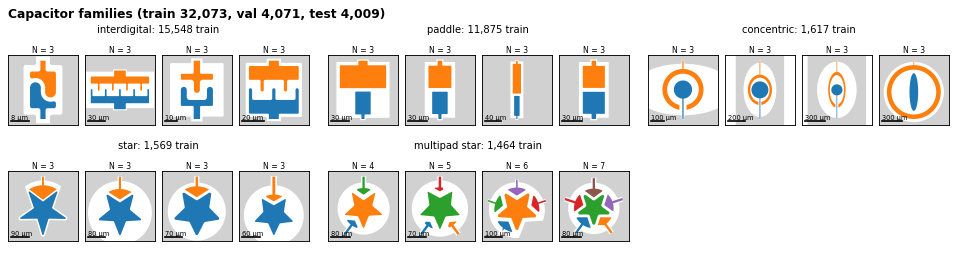

In [24]:
atlas("Capacitor families");

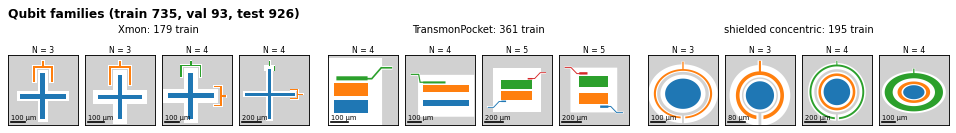

In [25]:
atlas("Qubit families");

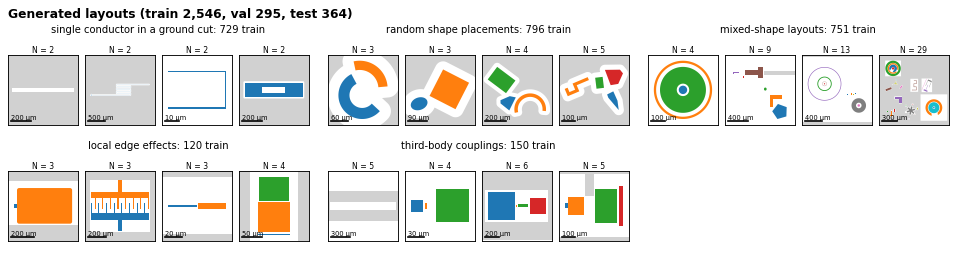

In [26]:
atlas("Generated layouts");

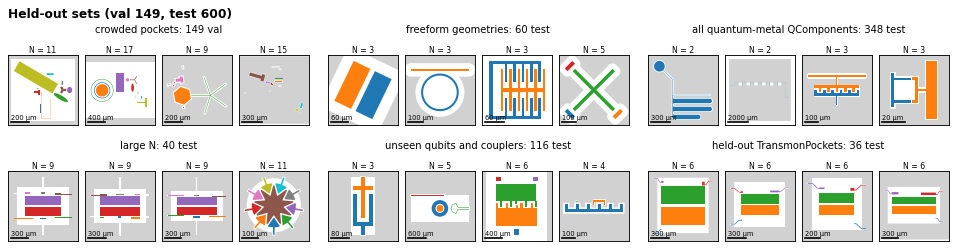

In [27]:
atlas("Held-out sets");

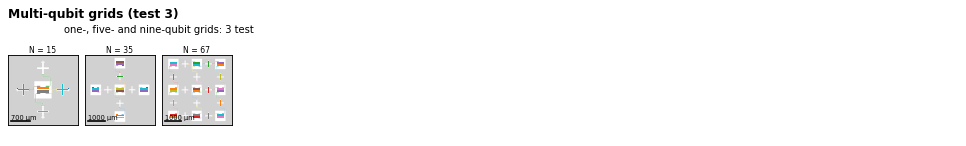

In [28]:
atlas("Multi-qubit grids");

The capacitor and qubit families are what the models were mainly trained on. The generated layouts fill in the physics around them (lone conductors, random placements, edge effects, a third body nearby), and the held-out sets and grids check the models on layouts they never saw. Now let's meet the swept families one by one.

## Meeting the families

Numbers without a picture are dangerous, so before we read any matrix we'll **rebuild each design with its SQuADDS component** and look at its metal and its ports. Three small helpers do this.

`build` takes a `design_id`, reads its stored options and instantiates the component in a fresh quantum-metal design:

In [29]:
from qiskit_metal import designs as metal_designs

from squadds.components import get_component_class
from squadds.database.planar_capacitance_view import QGEOMETRY_NETS, design_options_for, net_name


def build(design_id):
    """Rebuild a dataset design with its SQuADDS (Qiskit Metal) component class."""
    row = pdb.designs(design_ids=[design_id]).iloc[0]
    options = design_options_for(row.collection, row.component_class, pdb.params([design_id])[design_id])
    design = metal_designs.DesignPlanar({}, overwrite_enabled=True)
    component = get_component_class(row.component_class)(design, "component", options=options)
    design.rebuild()
    return component

`plot_metal` draws the ground in grey (its etch in white), every conductor in its own color with its net label (`N`, `S`, `P1`, ... and the SQuADDS name in brackets), and the **pins** of the component as red arrows. The pins are the ports, where a resonator, a feed line or a bus attaches in the full chip. Since quantum-metal works in mm, we scale to µm.

In [30]:
from shapely import affinity
from shapely.ops import unary_union


def metal_of(component):
    """Conductor bodies [(net label, geometry)] and ground etch [geometry] of a component, in µm."""
    nets, metal, etch = QGEOMETRY_NETS.get(type(component).__name__, {}), [], []
    for table in ("poly", "path"):
        df = component.design.qgeometry.tables[table]
        for r in df[~df["helper"].astype(bool)].itertuples():
            g = r.geometry if table == "poly" else r.geometry.buffer(r.width / 2, cap_style="flat")
            g = affinity.scale(g, 1e3, 1e3, origin=(0, 0))
            (etch if r.subtract else metal).append((nets.get(r.name), g))
    union = unary_union([g for _, g in metal])
    bodies = []
    for body in getattr(union, "geoms", [union]):
        labels = sorted({lab for lab, g in metal if lab and body.intersects(g)})
        bodies.append((labels[0] if len(labels) == 1 else "?", body))
    return bodies, [g for _, g in etch]

In [31]:
from matplotlib.patches import PathPatch
from matplotlib.path import Path as MplPath
from shapely.geometry.polygon import orient


def fill(ax, geometry, **kwargs):
    """Fill a shapely (multi)polygon, holes included."""
    for p in getattr(geometry, "geoms", [geometry]):
        rings = [np.asarray(r.coords) for r in (orient(p).exterior, *orient(p).interiors)]
        codes = [[MplPath.MOVETO] + [MplPath.LINETO] * (len(r) - 2) + [MplPath.CLOSEPOLY] for r in rings]
        ax.add_patch(PathPatch(MplPath(np.concatenate(rings), np.concatenate(codes)), lw=0, **kwargs))


def plot_metal(component, net_order, title="", ax=None):
    """Ground in grey, etch in white, conductors colored and named, pins (ports) as red arrows."""
    ax = ax or plt.subplots(figsize=(5.5, 5.5))[1]
    bodies, etch = metal_of(component)
    x0, y0, x1, y1 = unary_union([b for _, b in bodies] + etch).bounds
    pad, cls = 0.12 * max(x1 - x0, y1 - y0), type(component).__name__
    ax.fill([x0 - pad, x1 + pad, x1 + pad, x0 - pad], [y0 - pad, y0 - pad, y1 + pad, y1 + pad], color="0.82", lw=0)
    for g in etch:
        fill(ax, g, color="white")
    for label, body in sorted(bodies, key=lambda b: net_order.index(b[0]) if b[0] in net_order else 99):
        color = plt.cm.tab10(net_order.index(label) % 10 if label in net_order else 9)
        fill(ax, body, color=color, label=f"{label} ({net_name(cls, label)})")
    for name, pin in component.pins.items():
        (x, y), (dx, dy) = 1e3 * pin["middle"], 0.6 * pad * pin["normal"]
        ax.annotate(name, xy=(x, y), xytext=(x + dx, y + dy), color="crimson", fontsize=8,
                    arrowprops=dict(arrowstyle="<-", color="crimson"))
    ax.set_aspect("equal")
    ax.set(xlabel="x (µm)", ylabel="y (µm)", title=title)
    ax.legend(loc="upper left", fontsize=8, framealpha=0.9)
    return ax

`named_matrix` reads the Q3D label of a design (a pandas DataFrame in fF, ground first) and names its rows and columns the way the SQuADDS rows do (`ground`, `north`, `cross`, `pad_2`, ...). `pick` chooses the first validation design of a collection, with the largest $N$ unless we ask for one.

In [32]:
def named_matrix(design_id):
    """Q3D Maxwell matrix of a design (fF, ground first), with SQuADDS net names."""
    C = pdb.labels([design_id])[design_id]
    cls = pdb.designs(design_ids=[design_id]).component_class.iloc[0]
    names = {lab: net_name(cls, lab) for lab in C.index}
    return C.rename(index=names, columns=names).round(3)


def pick(collection, n_conductors=None):
    """First validation design of a collection (largest N unless n_conductors is given)."""
    d = pdb.designs(collection=collection, split="val", n_conductors=n_conductors)
    d = d.sort_values(["n_conductors", "design_id"], ascending=[False, True])
    return d.design_id.iloc[0]


def show(design_id):
    row = pdb.designs(design_ids=[design_id]).iloc[0]
    title = f"{row.paper_family}: {design_id} (N = {row.n_conductors})"
    return plot_metal(build(design_id), list(row.net_order), title=title)

### Paddle capacitors

We start with an old friend in a new shape. `GeneralizedCapNInterdigital` is the interdigital capacitor that already lives in SQuADDS. The paddle sweep gives each side its own finger width (`north_finger_width`, `south_finger_width`), so with few, wide fingers the comb turns into two facing paddles. Two signal conductors and the ground make $N = 3$.

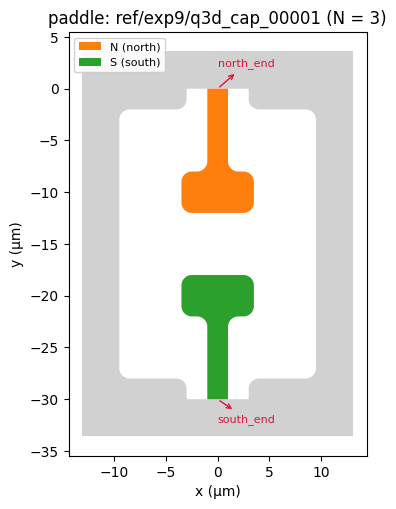

In [33]:
paddle = pick("exp9")
show(paddle);

The north body (with its port `north_end`) and the south body (port `south_end`) each end in a CPW stub, so this is a series coupling capacitor between two lines. Here is its matrix:

In [34]:
named_matrix(paddle)

,ground,north,south
ground,20.998,-2.131,-2.131
north,-2.131,2.345,-0.192
south,-2.131,-0.192,2.345


The coupling we design for is the mutual capacitance $C^{\rm mutual}_{NS} = -C_{NS}$. The diagonal entries are the total capacitance of each body to everything else. Let's add up each row:

In [35]:
named_matrix(paddle).sum(axis=1).round(6)

ground    16.736
north      0.022
south      0.022
dtype: float64

The signal rows nearly close. What is left over is the capacitance of each body to infinity, since Q3D solves the chip inside a finite box rather than in a perfectly closed ground. The ground row keeps a large remainder because the ground plane is by far the biggest conductor and has the most capacitance to the far field. So we design with the mutual (off-diagonal) entries, and keep in mind that the ground self term depends on how big the simulated chip is.

### Concentric capacitors

`GeneralizedCapConcentric` is a round island inside a ring, both inside a round pocket in the ground plane. The ring (`N`, north) is fed by a CPW stub from the north. In some designs the island (`S`, south) is fed by a stub from the south through a gap in the ring. In others, like this one, it floats. The ring screens the island from the ground, so the island-to-ring coupling is large for its footprint.

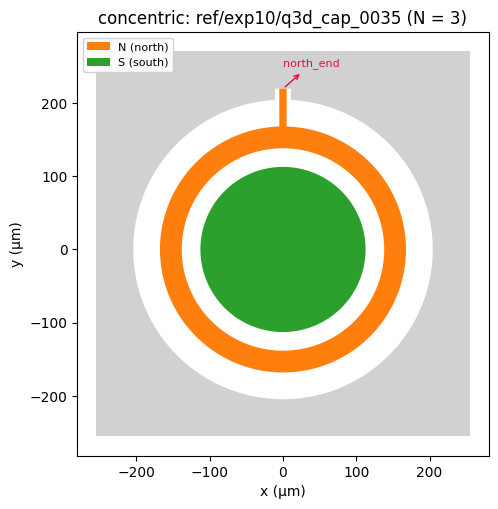

In [36]:
concentric = pick("exp10")
show(concentric);

In [37]:
named_matrix(concentric)

,ground,north,south
ground,147.854,-85.454,-31.646
north,-85.454,136.567,-47.864
south,-31.646,-47.864,82.245


### Star couplers

`GeneralizedCapStar` is a star-shaped island (`S`) in a circular ground pocket, with a pad (`N`, called `pad_0` in SQuADDS) tucked into one of its valleys. The star is the coupler, and the pad is where one qubit or resonator attaches.

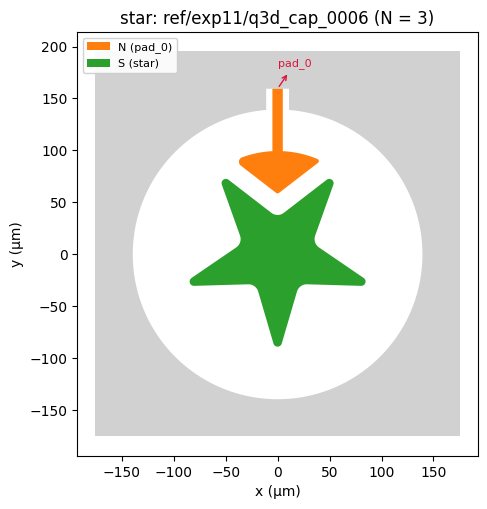

In [38]:
star = pick("exp11")
show(star);

In [39]:
named_matrix(star)

,ground,pad_0,star
ground,75.852,-14.301,-30.539
pad_0,-14.301,20.891,-6.194
star,-30.539,-6.194,38.326


### Multipad star couplers

The same star with a pad in **several** valleys is one coupler that talks to several qubits at once. Now the pad-to-pad entries matter too. They are the direct (unwanted) couplings between the circuits on different pads, a number a pairwise table cannot give us.

<details>
<summary><b>Rebuilt multipad stars differ slightly from the solved GDS</b></summary>

The multipad star GDS files went through an export step after drawing that the stored options do not replay exactly. A rebuild matches the component but not every vertex of the solved GDS. Their SQuADDS rows carry `geometry_reproducible = False`, and the label always belongs to the GDS file in the dataset.

</details>

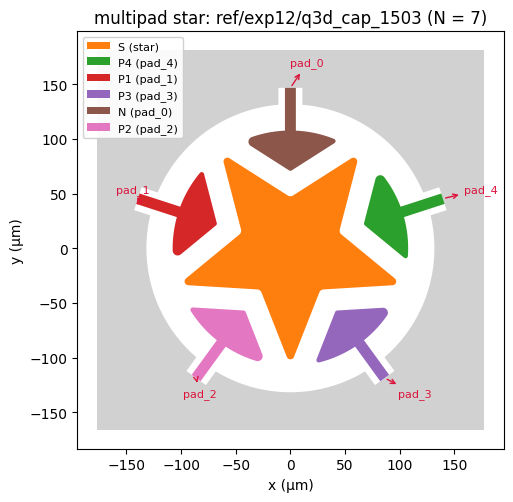

In [40]:
multipad = pick("exp12")
show(multipad);

In [41]:
named_matrix(multipad)

,ground,star,pad_4,pad_1,pad_3,pad_0,pad_2
ground,124.200,-27.459,-13.557,-13.563,-13.590,-12.334,-12.763
star,-27.459,55.984,-5.490,-5.491,-5.502,-5.493,-5.145
pad_4,-13.557,-5.490,20.107,-0.063,-0.331,-0.332,-0.059
pad_1,-13.563,-5.491,-0.063,20.109,-0.064,-0.332,-0.322
pad_3,-13.590,-5.502,-0.331,-0.064,20.109,-0.064,-0.284
pad_0,-12.334,-5.493,-0.332,-0.332,-0.064,18.890,-0.060
pad_2,-12.763,-5.145,-0.059,-0.322,-0.284,-0.060,18.887


Let's line up the couplings of the star to each of its pads, and the largest pad-to-pad one:

In [42]:
C = named_matrix(multipad)
pads = [n for n in C.index if n.startswith("pad_")]
pd.Series({**{f"star-{p}": -C.loc["star", p] for p in pads},
           "largest pad-pad": max(-C.loc[a, b] for a in pads for b in pads if a < b)}, name="mutual (fF)").round(3)

star-pad_4         5.490
star-pad_1         5.491
star-pad_3         5.502
star-pad_0         5.493
star-pad_2         5.145
largest pad-pad    0.332
Name: mutual (fF), dtype: float64

### Xmon qubits

`Xmon` is the cross-shaped transmon in a ground pocket with one or two claws: a readout claw (`N`, `claw`) and, optionally, a bus claw (`P1`, `bus_claw`). The cross (`S`) is the qubit island. Its junction goes from the cross to the ground and is not part of the capacitance problem. Its geometry and stack differ from the existing SQuADDS `TransmonCross` rows (continuous sweeps, 350 µm silicon), so it gets its own component and its own config. Here is one with both claws:

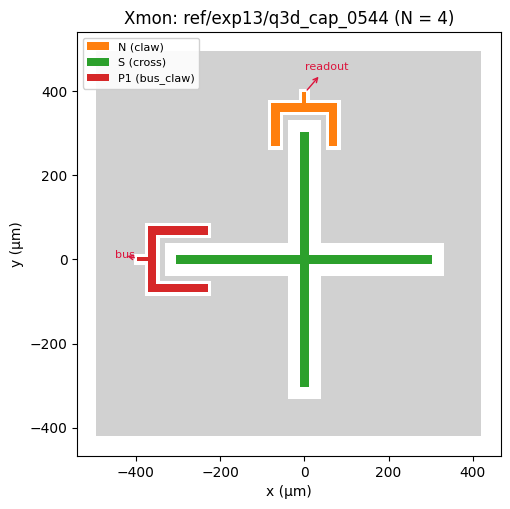

In [43]:
xmon = pick("exp13", n_conductors=4)
show(xmon);

In [44]:
named_matrix(xmon)

,ground,claw,cross,bus_claw
ground,337.954,-59.763,-146.468,-72.741
claw,-59.763,61.904,-1.851,-0.033
cross,-146.468,-1.851,152.413,-2.768
bus_claw,-72.741,-0.033,-2.768,75.855


For a grounded transmon, the total capacitance of the island is the Maxwell diagonal of the cross, $C_\Sigma = C_{\rm cross, cross}$, which counts both claws, and the charging energy is $E_C = e^2 / 2 C_\Sigma$:

In [45]:
from scipy.constants import e, h

C_sigma = named_matrix(xmon).loc["cross", "cross"] * 1e-15
print(f"C_sigma = {C_sigma * 1e15:.2f} fF, E_C = {e**2 / (2 * C_sigma) / h / 1e6:.1f} MHz")

C_sigma = 152.41 fF, E_C = 127.1 MHz


### TransmonPocket qubits

The `TransmonPocket` of quantum-metal is a **floating** transmon: two pads (`S` = `pad_top`, `P1` = `pad_bot`) in a pocket, with one or two coupler pads (`N` = `readout_pad`, `P2` = `bus_pad`) reaching in. Neither pad is grounded, so the qubit is the differential mode of the two pads, and we need the whole matrix to get its $E_C$ (Tutorial 13 does exactly that).

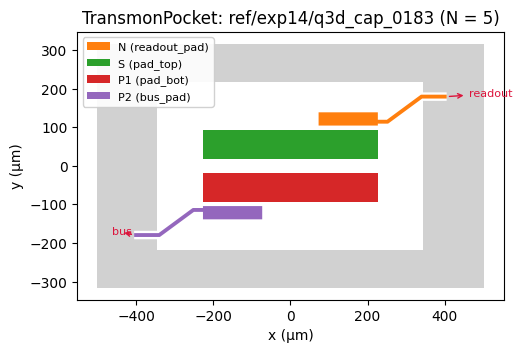

In [46]:
pocket = pick("exp14")
show(pocket);

In [47]:
named_matrix(pocket)

,ground,readout_pad,pad_top,pad_bot,bus_pad
ground,220.821,-32.181,-40.914,-40.918,-31.944
readout_pad,-32.181,50.944,-16.553,-1.762,-0.112
pad_top,-40.914,-16.553,88.720,-28.466,-1.762
pad_bot,-40.918,-1.762,-28.466,88.723,-16.552
bus_pad,-31.944,-0.112,-1.762,-16.552,50.707


### Shielded concentric capacitors

`ShieldedCapConcentric` is a concentric capacitor (`S` = `inner`, `N` = `outer`) with extra **guard** conductors (`P1`, `P2`, ... = `guard_1`, `guard_2`, ...) around it, each its own net. Guards are how we shield a sensitive node, and their effect is the kind of three-body physics only a full matrix captures.

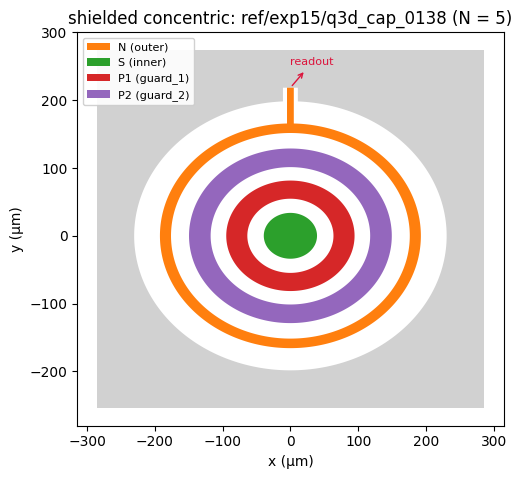

In [48]:
shielded = pick("exp15")
show(shielded);

In this one, the small inner island sits inside two guard rings, and the outer ring (the one with the port) wraps around all of them. Let's see what the guards do:

In [49]:
named_matrix(shielded)

,ground,outer,inner,guard_1,guard_2
ground,178.604,-79.010,-3.671,-14.028,-34.766
outer,-79.010,130.520,-1.197,-6.145,-42.740
inner,-3.671,-1.197,22.199,-13.950,-3.173
guard_1,-14.028,-6.145,-13.950,68.622,-33.784
guard_2,-34.766,-42.740,-3.173,-33.784,115.772


The island talks mostly to the guard right next to it, while its direct coupling to the outer ring is small: the guards soak up its field. Whether a guard helps or hurts then depends on what we connect it to, and only the full matrix can tell us.

We have met all the families. Let's now take **one** design (the two-claw Xmon) and look at everything the dataset knows about it.

## One design, every raw table

### The simulation and its QC flags

Before we design with a label or train on it, we want to know how it was solved and whether it passed QC. `simulations` has one row per solve: the solver and its setup, the stack, the convergence, the solve time, and the label QC flags recomputed from the export (symmetry, signs, row closure, positive definiteness and convergence). The **reference** solve is the one whose last pass is the label.

In [50]:
sim = pdb.simulations([xmon], role="reference")
qc_columns = ["solver", "eps_r", "substrate_um", "passes_completed", "converged", "delta_pct_final", "cores", "solve_s",
              "qc_symmetric", "qc_signs", "qc_closure", "qc_pd", "qc_convergence", "qc_ok"]
sim[qc_columns].T

,0
solver,Ansys Q3D Extractor
eps_r,11.45
substrate_um,350.0
passes_completed,19
converged,True
delta_pct_final,0.048635
cores,8
solve_s,2467.421
qc_symmetric,True
qc_signs,True


The QC flags let us filter the whole dataset in one line. Here is the fraction of reference solves of each family that pass each check, and how many of them reached their convergence target:

In [51]:
flags = ["qc_symmetric", "qc_signs", "qc_closure", "qc_pd", "qc_ok"]
sims = pdb.simulations(role="reference", columns=["design_id", "qc_convergence", *flags])
sims = sims.merge(sweeps[["design_id", "paper_family"]], on="design_id")
rates = sims[flags].astype(float).groupby(sims.paper_family).mean().round(4)
rates.join(pd.crosstab(sims.paper_family, sims.qc_convergence.fillna("not recorded")))

,qc_symmetric,qc_signs,qc_closure,qc_pd,qc_ok,converged,unrecorded
paper_family,,,,,,,
TransmonPocket,1.0,1.0,1.0,1.0,1.0000,580,0
Xmon,1.0,1.0,1.0,1.0,0.9936,775,5
concentric,1.0,1.0,1.0,1.0,1.0000,0,1981
interdigital,1.0,1.0,1.0,1.0,1.0000,0,19383
multipad star,1.0,1.0,1.0,1.0,1.0000,0,1830
paddle,1.0,1.0,1.0,1.0,1.0000,0,15000
shielded concentric,1.0,1.0,1.0,1.0,1.0000,400,0
star,1.0,1.0,1.0,1.0,1.0000,0,1959


Every matrix passes the symmetry, sign, closure and positive-definiteness checks. What differs is how convergence was recorded. A solve counts as converged when the change between its last two adaptive passes (`delta_pct_final`) is below the solver's own target (`delta_target_pct`). Let's look at those numbers family by family:

In [52]:
cols = ["design_id", "passes_completed", "delta_pct_final", "delta_target_pct"]
conv = pdb.simulations(role="reference", columns=cols).merge(sweeps[["design_id", "paper_family"]], on="design_id")
conv.groupby("paper_family")[cols[1:]].median().round(3)

,passes_completed,delta_pct_final,delta_target_pct
paper_family,,,
TransmonPocket,14.0,0.040,0.05
Xmon,20.0,0.038,0.05
concentric,14.0,NaN,NaN
interdigital,12.0,NaN,NaN
multipad star,16.0,NaN,NaN
paddle,17.0,NaN,NaN
shielded concentric,17.0,0.037,0.05
star,16.0,NaN,NaN


For the Xmon, `TransmonPocket` and shielded concentric solves, the final change sits just under the target. For the `exp6` to `exp12` sweeps (interdigital, paddle, concentric and both stars), the exports recorded no final change or target, so their convergence is `unrecorded`. If a study needs confirmed convergence only, `qc_convergence == "converged"` is the one-line filter.

<details>
<summary><b>What "unrecorded" means for a label</b></summary>

An `unrecorded` convergence is neither confirmed nor refuted. These solves still pass `qc_ok`, which fails only for a truncated solve or one recorded above its target. Their label is the last complete pass, and wherever the pass history was kept, `label_passes` (next) lets us judge the convergence ourselves.

</details>

### How the label converged

`label_passes` keeps every adaptive pass of the solve, in the same long format as the labels. Let's watch the mutual capacitances of our Xmon settle, relative to their final value:

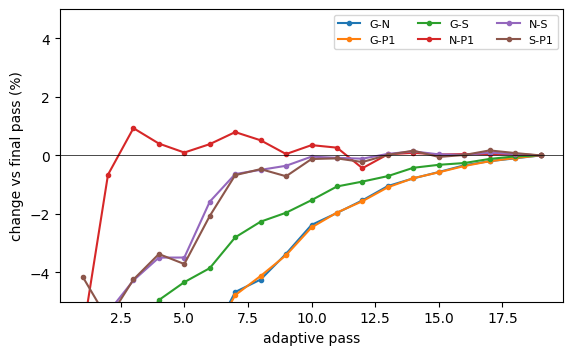

In [53]:
passes = pdb.label_passes([xmon])
mutual = passes[passes.a_idx < passes.b_idx]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for (a, b), g in mutual.groupby(["net_a", "net_b"]):
    g = g.sort_values("pass")
    ax.plot(g["pass"], 100 * (g.C_fF / g.C_fF.iloc[-1] - 1), "o-", ms=3, label=f"{a}-{b}")
ax.set(xlabel="adaptive pass", ylabel="change vs final pass (%)", ylim=(-5, 5))
ax.axhline(0, color="k", lw=0.5)
ax.legend(ncol=3, fontsize=8);

### The GDS that was solved

`gds_path` gives the local path of the GDS file of a design (downloading it from Hugging Face when needed). The dataset layer map is simple: the **ground plane on layer 1/0** and **every signal conductor on layer 1/10**, one connected body per conductor.

In [54]:
gds = pdb.gds_path(xmon)
gds.name, f"{gds.stat().st_size / 1e3:.1f} kB"

('q3d_cap_0544.gds', '3.4 kB')

In [55]:
from shapely.geometry import Polygon


def plot_gds(path, ax):
    """Ground (1/0) in grey and each conductor body on 1/10 in its own color."""
    cell = gdstk.read_gds(str(path), unit=1e-6).top_level()[0]
    signal = []
    for poly in cell.polygons:
        if (poly.layer, poly.datatype) == (1, 0):
            ax.fill(*poly.points.T, color="0.82", lw=0)
        elif (poly.layer, poly.datatype) == (1, 10):
            signal.append(Polygon(poly.points).buffer(0))
    union = unary_union(signal)
    for k, body in enumerate(getattr(union, "geoms", [union])):
        fill(ax, body, color=plt.cm.Set2(k % 8))
    ax.set_aspect("equal")
    ax.set(xlabel="x (µm)", title=f"{path.name}: {k + 1} conductors + ground")
    return ax

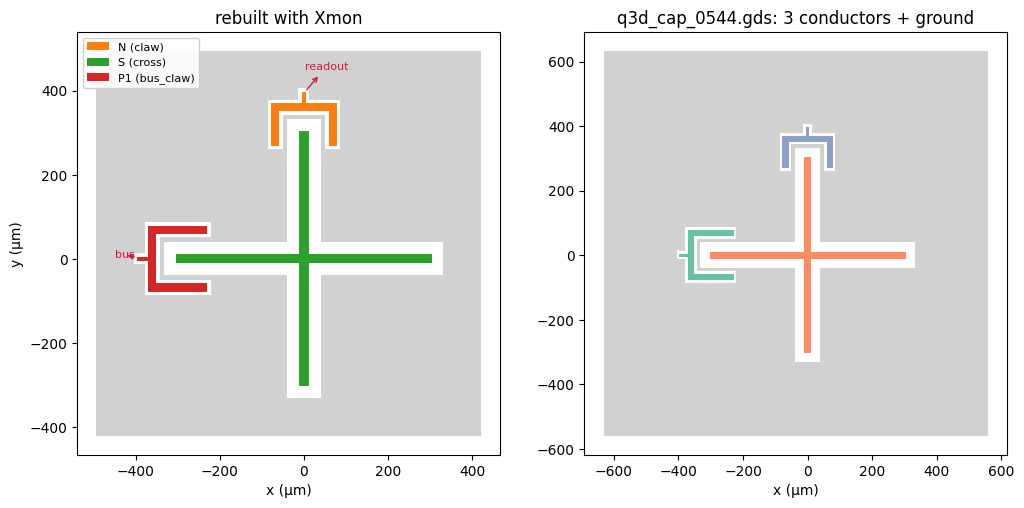

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
plot_metal(build(xmon), list(pdb.designs(design_ids=[xmon]).net_order.iloc[0]), "rebuilt with Xmon", ax=axes[0])
plot_gds(gds, axes[1]);

On the left is the component SQuADDS rebuilds from the stored options. On the right is the file Q3D solved, with its ground plane cut to the chip. Same metal, same three conductors plus ground.

## The processed tables

The raw tables describe what was simulated. The processed tables are what the planar capacitance models read, and they are useful on their own: to compare designs, to check a label against physics, or to train a model.

### The geometric embedding

The networks do not read polygons. Each layout is turned into vectors by the embedding `planar-capacitance-graph-v1`:

- one **conductor vector** per conductor (60 features, ground = node 0),
- one **pair vector** per pair of conductors (42 features),
- one **global vector** (4 features): log chip area, log pocket area, log substrate thickness and the effective permittivity.

<details>
<summary><b>What goes into the conductor and pair vectors</b></summary>

- Conductor vector: area, perimeter, width, elongation, compactness, solidity, holes, Fourier descriptors of the outline and a granulometry of its widths. The stored table adds a 61st column, a flag for a missing width.
- Pair vector: minimum distance, facing length, a histogram of separations and its moments, the ground-pair flag, and how crowded the neighbourhood is.

</details>

In [57]:
emb = pdb.embedding([xmon])[xmon]
{part: emb[part].shape for part in ("nodes", "edges")}, len(emb["globals"])

data/geometric_embedding/nodes-test.parq(…):   0%|          | 0.00/3.57M [00:00<?, ?B/s]

data/geometric_embedding/nodes-train.par(…):   0%|          | 0.00/20.1M [00:00<?, ?B/s]

data/geometric_embedding/nodes-val.parqu(…):   0%|          | 0.00/3.02M [00:00<?, ?B/s]

data/geometric_embedding/edges-test.parq(…):   0%|          | 0.00/3.79M [00:00<?, ?B/s]

data/geometric_embedding/edges-train.par(…):   0%|          | 0.00/21.0M [00:00<?, ?B/s]

data/geometric_embedding/edges-val.parqu(…):   0%|          | 0.00/4.20M [00:00<?, ?B/s]

data/geometric_embedding/globals-test.pa(…):   0%|          | 0.00/68.5k [00:00<?, ?B/s]

data/geometric_embedding/globals-train.p(…):   0%|          | 0.00/407k [00:00<?, ?B/s]

data/geometric_embedding/globals-val.par(…):   0%|          | 0.00/56.8k [00:00<?, ?B/s]

({'nodes': (4, 69), 'edges': (6, 52)}, 11)

In [58]:
emb["nodes"][["node_idx", "net", "log_area", "log_perimeter", "log_width", "compactness", "role_ground"]].round(3)

,node_idx,net,log_area,log_perimeter,log_width,compactness,role_ground
0,0,G,11.754,8.394,4.053,0.082,1.0
1,1,N,8.789,6.599,2.883,0.153,0.0
2,2,S,10.201,7.795,3.099,0.057,0.0
3,3,P1,9.000,6.793,2.900,0.128,0.0


In [59]:
emb["edges"][["net_a", "net_b", "is_ground_pair", "log_dmin", "log_cps"]].round(3)

,net_a,net_b,is_ground_pair,log_dmin,log_cps
0,G,N,1.0,2.088,7.593
1,G,S,1.0,3.344,8.037
2,G,P1,1.0,2.088,7.680
3,N,S,0.0,3.857,6.540
4,N,P1,0.0,5.494,5.669
5,S,P1,0.0,3.857,6.630


In [60]:
{k: v for k, v in emb["globals"].items() if k.startswith(("log_", "eps", "n_"))}

{'n_conductors': 4,
 'log_chip_area': 14.16441822052002,
 'log_pocket_area': 11.754310607910156,
 'log_substrate_t': 5.857933044433594,
 'eps_eff': 6.224999904632568}

### Two physics priors

The models do not learn the matrix from scratch. They start from a physics solution and learn the small correction it misses. The dataset stores two thin-film method-of-moments (MoM) solutions of every layout, computed from the GDS alone, with no learned parameter:

- `physics_prior`: the physics prior, one coarse solve with $p = 0.375$ panels per gap (cheap and rough),
- `optimized_physics_prior`: the extrapolated (optimized) prior, two solves at $p = 1.5$ and $p = 3$, extrapolated entry by entry, $C^{R} = \exp\left(2 \log C_{3} - \log C_{1.5}\right)$, the $R(1.5, 3)$ prior the planar capacitance models start from.

Both come back as Maxwell matrices, named like the labels. Here are the mutual capacitances ($-C_{ij}$) of our Xmon:

In [61]:
C = pdb.labels([xmon])[xmon]
iu = np.triu_indices(len(C), 1)
matrices = {"physics prior": pdb.physics_prior([xmon])[xmon],
            "extrapolated prior": pdb.optimized_physics_prior([xmon])[xmon], "Q3D label": C}
pd.DataFrame({k: -M.loc[C.index, C.index].to_numpy()[iu] for k, M in matrices.items()},
             index=[f"{C.index[i]}-{C.index[j]}" for i, j in zip(*iu)]).round(3)

data/physics_prior/physics_prior-test.pa(…):   0%|          | 0.00/728k [00:00<?, ?B/s]

data/physics_prior/physics_prior-train.p(…):   0%|          | 0.00/3.98M [00:00<?, ?B/s]

data/physics_prior/physics_prior-val.par(…):   0%|          | 0.00/784k [00:00<?, ?B/s]

data/optimized_physics_prior/optimized_p(…):   0%|          | 0.00/930k [00:00<?, ?B/s]

data/optimized_physics_prior/optimized_p(…):   0%|          | 0.00/5.23M [00:00<?, ?B/s]

data/optimized_physics_prior/optimized_p(…):   0%|          | 0.00/1.05M [00:00<?, ?B/s]

,physics prior,extrapolated prior,Q3D label
G-N,49.724,60.035,59.763
G-S,133.274,146.393,146.468
G-P1,60.820,72.898,72.741
N-S,1.651,1.858,1.851
N-P1,0.031,0.031,0.033
S-P1,2.512,2.791,2.768


What does a prior cost? Both were computed once on x86 cluster nodes and are stored, so reading them is free. Recomputing them for a five-pad star took 0.10 s (the physics prior) and 1.79 s (the extrapolated prior) on 2 threads of an Intel Xeon E5-2640 v4 in [Tutorial 11](https://lfl-lab.github.io/SQuADDS/source/tutorials/Tutorial-11_Predicting_Capacitance_Matrices_from_GDS.html), against minutes to an hour for a Q3D solve (the reference solve of our Xmon took 2,467 s on 8 cores).

### The model input

`model_input` packs, per layout, exactly what the released `QCap` model consumes: the conductor vectors `X`, the pair vectors `E`, the global vector `G`, the two optimized-prior solves of every pair `pri` (at $p = 1.5$ and $p = 3$), and `sig`, which marks the signal conductors (the ground is `False`). Everything is flattened into lists, one row per layout:

In [62]:
mi = pdb.model_input([xmon]).iloc[0]
n = int(mi.n_conductors)
pairs = n * (n - 1) // 2
pd.Series({"N": n, "net_order": list(mi.net_order), "pairs": pairs, "X per conductor": len(mi.X) / n,
           "E per pair": len(mi.E) / pairs, "G": len(mi.G), "pri per pair": len(mi.pri) / pairs, "sig": list(mi.sig)})

data/model_input/model_input-test.parque(…):   0%|          | 0.00/7.03M [00:00<?, ?B/s]

data/model_input/model_input-train.parqu(…):   0%|          | 0.00/40.4M [00:00<?, ?B/s]

data/model_input/model_input-val.parquet:   0%|          | 0.00/6.95M [00:00<?, ?B/s]

N                                          4
net_order                      [G, N, S, P1]
pairs                                      6
X per conductor                         61.0
E per pair                              42.0
G                                          4
pri per pair                             2.0
sig                [False, True, True, True]
dtype: object

### Designs that look alike: `nearest`

When we have a new idea, it helps to know which designs in the data look like it. Every layout can be pooled into one vector (the global features, $\log N$, and the mean and maximum of each conductor feature over the signal conductors), and `nearest` returns the closest designs in that space, by default within the same family. This measures **geometric** similarity. It is not a capacitance distance.

In [63]:
neighbours = pdb.nearest(concentric, k=4)
neighbours

,design_id,distance,collection,model_family,split
0,ref/exp10/q3d_cap_0004,1.242815,exp10,concentric,train
1,ref/exp10/q3d_cap_0183,1.257176,exp10,concentric,train
2,ref/exp10/q3d_cap_0117,1.489072,exp10,concentric,train
3,ref/exp10/q3d_cap_0224,1.545725,exp10,concentric,train


Let's look at our concentric capacitor next to its two nearest neighbours:

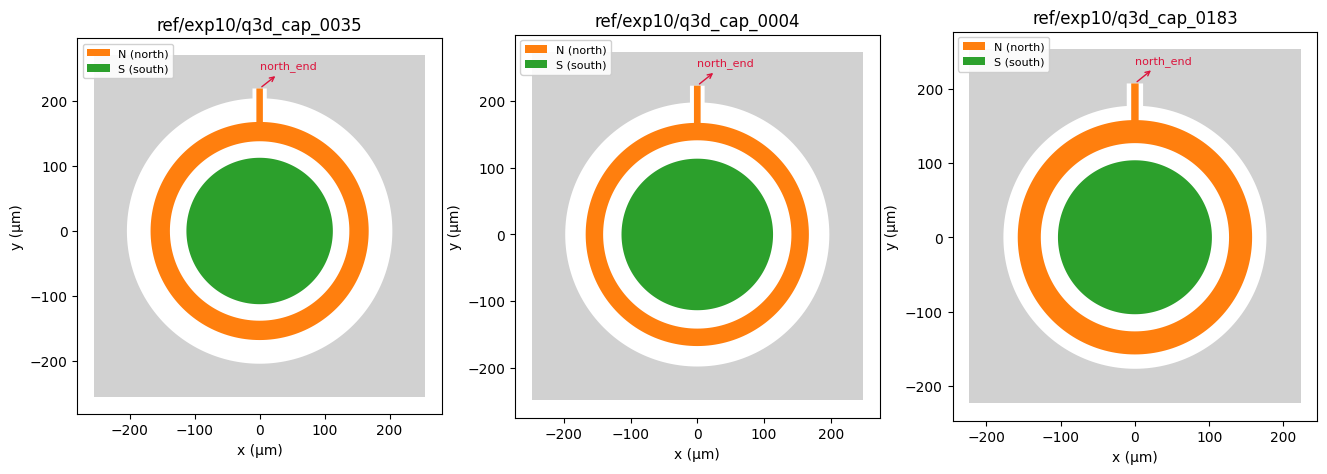

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, d in zip(axes, [concentric, *neighbours.design_id[:2]]):
    plot_metal(build(d), list(pdb.designs(design_ids=[d]).net_order.iloc[0]), d, ax=ax)

## The same data in the classic SQuADDS workflow

Everything above used the dataset's own tables. Most of the time, though, we want to pick a design from a target, as in [Tutorial 1](https://lfl-lab.github.io/SQuADDS/source/tutorials/Tutorial-1_Getting_Started_with_SQuADDS.html). For that, the dataset is a second **source** of `SQuADDS_DB`, converted on load to the usual row format (`design_options`, `sim_options`, `sim_results` with pairwise capacitances `<a>_to_<b>` in fF plus the signed `maxwell_matrix`, `notes`, `contributor`). The source is on by default, and here we name both sources:

In [65]:
from squadds import Analyzer, SQuADDS_DB

db = SQuADDS_DB(sources=("default", "planar_capacitance"))
db.enabled_sources()

['default', 'planar_capacitance']

The new configurations appear next to the existing ones, with the usual `component-ComponentClass-data_type` names:

In [66]:
db.get_configs()

['qubit-TransmonCross-cap_matrix',
 'cavity_claw-RouteMeander-eigenmode',
 'coupler-NCap-cap_matrix',
 'coupler-CapNInterdigitalTee-cap_matrix',
 'coupler-GeneralizedCapNInterdigital-cap_matrix',
 'coupler-GeneralizedCapConcentric-cap_matrix',
 'coupler-GeneralizedCapStar-cap_matrix',
 'coupler-ShieldedCapConcentric-cap_matrix',
 'qubit-Xmon-cap_matrix',
 'qubit-TransmonPocket-cap_matrix']


### A concentric capacitor with a capacitance target

Couplers don't have a Hamiltonian of their own, so we query them with a capacitance target directly. We select the system and the coupler exactly as for any other SQuADDS component:

In [67]:
db.unselect_all()
db.select_system("coupler")
db.select_coupler("GeneralizedCapConcentric")
concentric_df = db.create_system_df()
concentric_df[["north_to_south", "north_to_ground", "south_to_ground"]].describe().round(2)

,north_to_south,north_to_ground,south_to_ground
count,1787.00,1787.00,1787.00
mean,43.48,120.45,29.27
std,18.18,51.87,12.28
min,11.94,32.85,5.95
25%,28.97,83.48,20.29
50%,41.82,110.00,28.35
75%,55.91,144.42,37.26
max,149.76,396.95,79.44


Let's say our design calls for 25 fF between the ring and the island. `Analyzer.find_closest` finds the closest rows:

In [68]:
analyzer = Analyzer(db)
results = analyzer.find_closest({"north_to_south": 25.0}, num_top=3)
results[["design_id", "north_to_south", "north_to_ground", "south_to_ground"]]

,design_id,north_to_south,north_to_ground,south_to_ground
592,ref/exp10/q3d_cap_0663,24.994342,143.868413,11.382426
1651,ref/exp10/q3d_cap_1847,25.012531,125.438512,10.614550
1121,ref/exp10/q3d_cap_1259,24.982629,83.795927,11.497958


Each row still knows its `design_id`, so everything we did above works on it too. Here is the closest one:

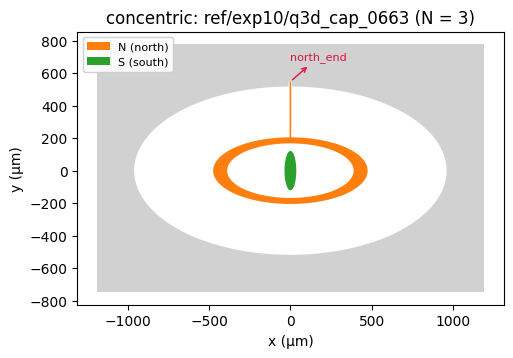

In [69]:
best = results.design_id.iloc[0]
show(best);

### An Xmon with a target frequency and anharmonicity

For qubits, `find_closest` takes Hamiltonian targets as in Tutorial 1. For the `Xmon` rows, SQuADDS takes $C_\Sigma$ as the full Maxwell diagonal of the cross, so a second claw is counted too.

In [70]:
db.unselect_all()
db.select_system("qubit")
db.select_qubit("Xmon")
xmon_df = db.create_system_df()
analyzer = Analyzer(db)
xmon_results = analyzer.find_closest({"qubit_frequency_GHz": 5.0, "anharmonicity_MHz": -210}, num_top=3)
xmon_results[["design_id", "qubit_frequency_GHz", "anharmonicity_MHz", "EC", "C_sigma_fF", "cross_to_claw"]]

,design_id,qubit_frequency_GHz,anharmonicity_MHz,EC,C_sigma_fF,cross_to_claw
113,ref/exp13/q3d_cap_0696,5.015470,-211.432941,0.192141,100.812421,6.180169
121,ref/exp13/q3d_cap_0704,5.015657,-211.450369,0.192156,100.804454,1.842175
146,ref/exp13/q3d_cap_0729,4.972937,-207.504249,0.188757,102.620181,1.509150


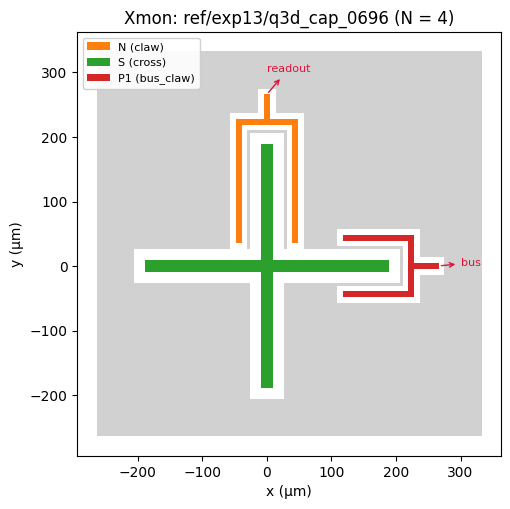

In [71]:
show(xmon_results.design_id.iloc[0]);

The `TransmonPocket` rows work the same way with `select_qubit("TransmonPocket")` (with the floating-transmon Hamiltonian). The other couplers use `select_coupler("GeneralizedCapStar")`, `select_coupler("ShieldedCapConcentric")` and the existing `select_coupler("GeneralizedCapNInterdigital")`, which the paddles join. [Tutorial 13](https://lfl-lab.github.io/SQuADDS/source/tutorials/Tutorial-13_From_Layout_to_Hamiltonian_with_ML.html) takes these rows all the way to a Hamiltonian.

### No row is stored twice

The interdigital sweeps (`exp6`, `exp7`, `exp8`) are mostly the very designs already in `SQuADDS/SQuADDS_DB`, so the planar capacitance dataset does not upload them again. Those designs carry a `squadds_db_ref` pointing to the existing row (repository, revision, config and row index). The SQuADDS view leaves them out, so they appear once, from `SQuADDS_DB`. Duplicates are found by `geom_hash`, a hash of each design's polygons rounded to 1 nm.

In [72]:
refs = pdb.designs(columns=["design_id", "collection", "squadds_db_ref"])
refs.groupby("collection").squadds_db_ref.apply(lambda s: s.notna().sum()).loc[lambda s: s > 0]

collection
campaign450        2
exp6            1556
exp7            1440
exp8           16379
multistack         9
Name: squadds_db_ref, dtype: int64

In [73]:
json.loads(refs.squadds_db_ref.dropna().iloc[0])

{'config': 'coupler-GeneralizedCapNInterdigital-cap_matrix',
 'gds_path': 'raw/GeneralizedCapNInterdigital/exp7/cap_0021.gds',
 'layouts_design_id': 'design:sha256:af13597be3a2f27e4db5f7711a9b9972e5742d5b105601542f3155bd0cc4df45',
 'layouts_repo': 'SQuADDS/SQuADDS_Layouts',
 'layouts_revision': '78f0b913c210f1c49fbb4495db0108efb4f2b9e7',
 'match': 'geom_hash',
 'repo': 'SQuADDS/SQuADDS_DB',
 'revision': '0e25705f54c343fb96571ff15b6fd8375ca899aa',
 'row_index': 2264,
 'source_id': 'exp7/cap_0021'}

## Splits, test labels, licence and contributors

### Which labels are public?

The splits are the ones of the paper that introduces the planar capacitance models. `train` and `val` labels are all public. The `test` layouts were set aside to score the models once, so **their geometry, embeddings and priors are public, but their labels are not** (they live in the private held-out repository `SQuADDS/SQuADDS_PlanarCapacitance-heldout`). A test design simply has no label:

In [74]:
test = pdb.designs(split="test", columns=["design_id", "collection", "paper_family", "notes"])
test_xmon = test[test.collection == "exp13"].design_id.iloc[0]
test_xmon, pdb.labels([test_xmon])

('ref/exp13/q3d_cap_0000', {})

There is one exception. The interdigital test designs (`exp6` to `exp8`) had their matrices public in `SQuADDS/SQuADDS_DB` long before, so their labels are in this dataset too, with a note that says so. Scores on them are therefore not blind.

In [75]:
test.groupby(test.notes.fillna("").str.contains("labels public")).size().rename("test designs")

notes
False    4016
True     1904
Name: test designs, dtype: int64

We never used a test label in this tutorial, and you should not either if you want to compare a model with the paper's numbers. Train on `train`, tune on `val`, and leave `test` alone.

### Licence and contributors

The dataset is released under **CC-BY-4.0**. Feel free to use it for anything but credit the people who made it and consider [supporting](https://dornsife.usc.edu/giving/) our [lab's research](https://dornsife.usc.edu/lfl/research/) :)

Every design records its contributor and licence:

In [76]:
who = pdb.designs(columns=["collection", "contributor_id", "licence_id"])
who.licence_id.value_counts()

licence_id
CC-BY-4.0    60159
Name: count, dtype: int64

And here is who contributed each of the parametric sweeps:

In [77]:
sweep_who = who[who.collection.str.fullmatch(r"exp\d+")]
pd.crosstab(sweep_who.collection, sweep_who.contributor_id).sort_index(key=lambda c: c.str[3:].astype(int))

contributor_id,sadman_shanto,saikat_das
collection,,
exp6,0,1563
exp7,0,1440
exp8,0,16380
exp9,0,15000
exp10,0,1981
exp11,0,1959
exp12,0,1833
exp13,1500,0
exp14,1500,0


## Next Steps...

In the next [tutorial](https://lfl-lab.github.io/SQuADDS/source/tutorials/Tutorial-13_From_Layout_to_Hamiltonian_with_ML.html), we will take layouts like these from GDS all the way to a Hamiltonian with the planar capacitance models, and plug the predictions into the usual SQuADDS workflow.

## License

<div style='width: 100%; background-color:#3cb1c2;color:#324344;padding-left: 10px; padding-bottom: 10px; padding-right: 10px; padding-top: 5px'>
    <h3>This code is a part of SQuADDS</h3>
    <p>Developed by Sadman Ahmed Shanto</p>
    <p>This tutorial is written by Sadman Ahmed Shanto and Claude Opus 5.5</p>
    <p>&copy; Copyright Sadman Ahmed Shanto & Eli Levenson-Falk 2026.</p>
    <p>This code is licensed under the MIT License. You may<br> obtain a copy of this license in the LICENSE.txt file in the root directory<br> of this source tree.</p>
    <p>Any modifications or derivative works of this code must retain this<br>copyright notice, and modified files need to carry a notice indicating<br>that they have been altered from the originals.</p>
</div>